# Kahramanmaraş 2023 · MMI Intensity Mapper demo

Bu not defteri `mmi_mapper` paketinin uçtan uca kullanımını gösterir:

1. Eski formül ile yayımlanmış IPE'lerin karşılaştırılması
2. Sonlu fay (GEM izi + Thingbaijam 2017) ve GMPE + GMICE zinciri
3. Mantık ağacı, %16/%50/%84 ve aşma olasılıkları
4. KOERI istasyonlarıyla doğrulama
5. Nüfus maruziyeti (PAGER mantığı) ve katmanlı harita

> Bu araç **olmuş** bir depremin etkisini tahmin eder; deprem öngörüsü yapmaz.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
pd.set_option("display.float_format", "{:,.2f}".format)
from mmi_mapper import ipe, observations as O
from mmi_mapper.model import Event, run_scenario, MODEL_LABELS
from mmi_mapper.uncertainty import add_uncertainty
from mmi_mapper.benchmark import predict_for_observations, metrics
from mmi_mapper.exposure import exposure
from mmi_mapper.grid import run_latlon_grid
from mmi_mapper.mapping import layered_map

## 1. Eski formül neden kaldırıldı?

In [2]:
r = np.array([25, 50, 100, 200, 300.0])
pd.DataFrame({"Repi (km)": r,
              "Eski formül": ipe.legacy_unverified(7.8, r, 10)[0],
              "Allen 2012 Rhyp": ipe.allen2012_rhyp(7.8, np.hypot(r, 10))[0],
              "Bayrak 2019 R3": ipe.bayrak2019(7.8, r, 10, "R3")[0]}).assign(
    **{"Fark (eski − Allen)": lambda d: d["Eski formül"] - d["Allen 2012 Rhyp"]})

,Repi (km),Eski formül,Allen 2012 Rhyp,Bayrak 2019 R3,Fark (eski − Allen)
0,25.00,9.22,7.95,8.72,1.27
1,50.00,8.80,7.46,7.73,1.34
2,100.00,8.30,6.74,6.71,1.56
3,200.00,7.66,5.88,5.70,1.77
4,300.00,7.17,5.36,5.10,1.82


## 2. Senaryo: Pazarcık Mw 7.8, büyük şehirler

In [3]:
ev = Event(7.8, 37.2256, 37.0143, 10.0, event_id="us6000jllz")
cities = {"Kahramanmaraş": (37.5753, 36.9228), "Antakya": (36.2023, 36.1613), "Gaziantep": (37.0662, 37.3833),
          "Malatya": (38.3552, 38.3095), "Adana": (36.9914, 35.3308)}
lat, lon = zip(*cities.values())
df, rup = run_scenario(ev, lat, lon)  # Vs30: USGS rasteri
df = add_uncertainty(df, finite=rup.is_finite)
df.index = list(cities)
print(rup.source, f"L = {rup.length:.0f} km, W = {rup.width:.0f} km")
df[["repi", "rjb", "rrup", "vs30", "legacy", "allen2012_rhyp", "allen2012_rrup", "bayrak2019", "kale2015_wgrw12",
    "lt_p16", "lt_p50", "lt_p84", "p_ge_7", "p_ge_8"]]

GEM GAF-DB izi (ME_TRCS056) + Thingbaijam 2017 L = 234 km, W = 18 km


,repi,rjb,rrup,vs30,legacy,allen2012_rhyp,allen2012_rrup,bayrak2019,kale2015_wgrw12,lt_p16,lt_p50,lt_p84,p_ge_7,p_ge_8
Kahramanmaraş,39.65,12.47,12.47,477.00,8.95,7.66,7.81,8.06,7.51,6.84,7.93,9.17,0.80,0.47
Antakya,136.76,19.30,20.23,353.20,8.03,6.36,7.52,6.25,7.37,6.52,7.64,8.89,0.72,0.38
Gaziantep,37.25,50.82,53.18,276.10,8.99,7.71,6.63,8.15,6.68,5.91,6.93,8.16,0.47,0.19
Malatya,169.51,65.77,65.77,373.00,7.83,6.09,6.41,5.94,6.21,5.46,6.46,7.54,0.30,0.09
Adana,151.88,102.78,102.78,243.80,7.93,6.23,5.93,6.10,6.09,5.22,6.19,7.31,0.23,0.07


Antakya'da Repi ≈ 137 km iken Rrup ≈ 20 km'dir: nokta kaynak varsayımı büyük depremlerde şiddeti ciddi biçimde düşük tahmin eder.

## 3. Doğrulama: USGS DYFI, AFAD ve KOERI gözlemleri

Fay geometrisi olarak USGS ShakeMap `rupture.json` kullanılır.

In [4]:
from mmi_mapper.rupture import build_rupture
usgs = pd.read_csv("../data/observations/usgs_observations.csv")
obs = pd.concat([O.load_koeri(event_id="us6000jllz"),
                 usgs[usgs.event_id == "us6000jllz"].drop(columns="event_id")], ignore_index=True)
sm_rup = build_rupture(ev.mag, ev.lat, ev.lon, ev.depth, rupture_geojson="../data/ruptures/us6000jllz_shakemap.geojson")
res, _ = predict_for_observations(ev, obs, rupture=sm_rup)
print(obs.source.value_counts().to_dict())
metrics(res, "source").query("model in ['Eski formül (doğrulanmamış)', 'Allen 2012 · Rrup', 'Kale 2015 → WGRW12', 'Mantık ağacı (ortalama)']")

{'AFAD (ShakeMap)': 241, 'USGS DYFI': 186, 'KOERI (ShakeMap)': 16, 'KOERI': 4, 'istasyon (ShakeMap)': 4}


,grup,model,N,sapma,RMSE,MAE,std
0,AFAD (ShakeMap),Eski formül (doğrulanmamış),241,-1.44,1.75,1.58,1.01
2,AFAD (ShakeMap),Allen 2012 · Rrup,241,0.38,0.79,0.64,0.70
4,AFAD (ShakeMap),Kale 2015 → WGRW12,241,0.67,0.96,0.78,0.68
6,AFAD (ShakeMap),Mantık ağacı (ortalama),241,0.42,0.79,0.64,0.68
7,KOERI,Eski formül (doğrulanmamış),4,-1.57,1.94,1.57,1.31
9,KOERI,Allen 2012 · Rrup,4,0.30,0.90,0.80,0.98
11,KOERI,Kale 2015 → WGRW12,4,0.54,0.95,0.88,0.90
13,KOERI,Mantık ağacı (ortalama),4,0.21,0.77,0.70,0.85
14,KOERI (ShakeMap),Eski formül (doğrulanmamış),16,-2.32,2.50,2.32,0.96
16,KOERI (ShakeMap),Allen 2012 · Rrup,16,-0.30,0.84,0.78,0.81


In [5]:
pd.read_csv("../results/geometry_sensitivity_kahramanmaras.csv")  # nokta kaynak vs. GEM vs. USGS fayı

,geometri,model,N,sapma,RMSE,N_yakın,RMSE_yakın
0,Nokta kaynak,Allen 2012 · Rrup,583,0.47,1.20,65,2.35
1,Nokta kaynak,Kale 2015 → WGRW12,583,0.65,1.39,65,2.73
2,Nokta kaynak,Mantık ağacı (ortalama),583,0.47,1.18,65,2.26
3,GEM izi + Thingbaijam 2017 (otomatik),Allen 2012 · Rrup,583,0.11,0.91,65,1.19
4,GEM izi + Thingbaijam 2017 (otomatik),Kale 2015 → WGRW12,583,0.32,1.05,65,1.37
5,GEM izi + Thingbaijam 2017 (otomatik),Mantık ağacı (ortalama),583,0.17,0.92,65,1.10
6,USGS fayı (ShakeMap / FFM; yoksa GEM),Allen 2012 · Rrup,583,0.09,0.88,65,1.15
7,USGS fayı (ShakeMap / FFM; yoksa GEM),Kale 2015 → WGRW12,583,0.30,1.02,65,1.36
8,USGS fayı (ShakeMap / FFM; yoksa GEM),Mantık ağacı (ortalama),583,0.15,0.88,65,1.07


In [6]:
pd.read_csv("../results/rmse_by_event.csv")  # altı büyük deprem, deprem bazında RMSE

,grup,N,Eski formül (doğrulanmamış),Allen 2012 · Rrup,Bayrak 2019 · R3,Kale 2015 → WGRW12,Mantık ağacı (ortalama)
0,Kahramanmaraş (Pazarcık) 2023,447,2.09,0.86,1.05,0.98,0.85
1,Kahramanmaraş (Elbistan) 2023,136,1.99,0.95,0.87,1.16,0.99
2,Elazığ (Sivrice) 2020,39,1.53,0.79,0.77,0.82,0.92
3,Sisam / İzmir 2020,491,2.64,0.95,1.39,0.93,0.87
4,Düzce 1999,86,2.06,1.18,1.21,1.11,1.21
5,Kocaeli (İzmit) 1999,125,2.08,1.11,1.40,1.05,1.12


## 4. ML artık modeli (Aşama 4)

In [7]:
pd.read_csv("../results/ml/cv_summary.csv")

,küme,yöntem,N,deprem,sapma,RMSE
0,tümü,omurga (Kale 2015 → WGRW12),949,332,-0.42,0.68
1,tümü,omurga + sabit kaydırma,949,332,0.00,0.54
2,tümü,omurga + LightGBM,949,332,0.00,0.45
3,Mw ≥ 6,omurga (Kale 2015 → WGRW12),54,18,-0.17,0.69
4,Mw ≥ 6,omurga + sabit kaydırma,54,18,0.24,0.71
5,Mw ≥ 6,omurga + LightGBM,54,18,-0.01,0.65
6,Rrup ≤ 50 km,omurga (Kale 2015 → WGRW12),138,87,-0.04,0.59
7,Rrup ≤ 50 km,omurga + sabit kaydırma,138,87,0.38,0.70
8,Rrup ≤ 50 km,omurga + LightGBM,138,87,-0.03,0.53
9,tümü · istasyon bazlı CV,omurga (Kale 2015 → WGRW12),949,332,-0.42,0.68


## 5. Nüfus maruziyeti ve katmanlı harita

In [8]:
table, places, _ = exposure(ev, 3.0, rupture=rup)
table.set_index("MMI").astype(int)

,%16,Medyan,%84
MMI,,,
I,0,0,0
II–III,25394,0,0
IV,9643450,489383,0
V,10518798,9179461,1034302
VI,4092977,10518798,8673608
VII,1202885,4005583,9597135
VIII,0,1290279,4831667
IX,0,0,1217195
X+,0,0,129597



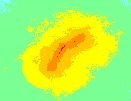
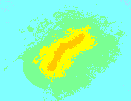
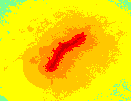
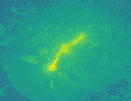
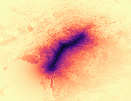
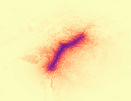

In [9]:
g, _ = run_latlon_grid(ev, 2.5, 0.05, rupture=rup)
layered_map(ev, g, rup, obs[obs.source != "USGS DYFI"], places)